# Collaborative Filtering Movie Recommender System
### Predicting User Ratings with Matrix Factorization (SVD)

---

## 1. The User-Item Interaction Matrix

### What is Collaborative Filtering?
Unlike Content-Based Filtering (which looks at movie genres and text tags), **Collaborative Filtering** relies on the collective wisdom and behavior of the community. The core intuition is simple:
> *"If User A and User B liked many of the same movies in the past, they probably have similar tastes and will agree on movies in the future."*

It recommends movies not by analyzing what the movie is about, but by recognizing patterns of shared preference between people.

---

### The User-Item Interaction Table
Imagine creating a massive grid or spreadsheet where:
- Each **row** represents an individual user ($u_1, u_2, \dots, u_m$).
- Each **column** represents a movie ($i_1, i_2, \dots, i_n$).
- Each **cell $(u, i)$** contains the rating that user $u$ gave to movie $i$ (e.g., $4.0$, $2.5$, $5.0$).

```
                Toy Story (1)   Jumanji (2)   Heat (6)   The Matrix (2571)
User 1               4.0            NaN         NaN            5.0
User 2               NaN            3.5         4.0            NaN
User 3               5.0            NaN         NaN            4.5
...
```

#### Why is this Table Extremely "Sparse"?
A catalog contains tens of thousands of movies, but an individual person only watches and rates a few dozen or hundred movies. As a result, **over 98% to 99% of the cells in this matrix are empty (`NaN`)**.

The fundamental mission of a Collaborative Filtering recommender is to **fill in those blank cells** with accurate predicted ratings ($\hat{r}_{ui}$). Once we estimate what rating a user would give to every movie they haven't seen yet, recommending movies is straightforward: simply present the unwatched movies with the highest predicted ratings!

In [1]:
# ==============================================================================
# Cell 1 Code: Load Ratings Dataset & Prepare for Matrix Factorization
# ==============================================================================

import sys
import subprocess

# Automatically verify and install required libraries in the active kernel
for pkg_name, import_name in [('seaborn', 'seaborn'), ('scikit-surprise', 'surprise')]:
    try:
        __import__(import_name)
    except ModuleNotFoundError:
        print(f"Installing '{pkg_name}' into the active notebook kernel environment...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg_name])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split
from collections import defaultdict

# Visual aesthetics configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110

print("Step 1: Preparing ratings data for Collaborative Filtering...")

# 1. Load movies metadata for titles and genres
movies_df = pd.read_csv('movies.csv')

# 2. Load ratings dataset
# We use a representative sample of 200,000 ratings to train the model quickly (~1.5s)
# while maintaining a rich density of active users and popular movies
ratings_sample = pd.read_csv(
    'ratings.csv',
    nrows=200000,
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}
)

num_users = ratings_sample['userId'].nunique()
num_movies = ratings_sample['movieId'].nunique()
num_ratings = len(ratings_sample)
total_possible_cells = num_users * num_movies
sparsity = (1.0 - (num_ratings / total_possible_cells)) * 100

print(f"- Number of unique users:   {num_users:,}")
print(f"- Number of unique movies:  {num_movies:,}")
print(f"- Total ratings in sample:  {num_ratings:,}")
print(f"- Matrix sparsity:          {sparsity:.2f}% empty cells")

# 3. Define the Surprise Reader format with valid rating boundaries (0.5 to 5.0)
reader = Reader(rating_scale=(0.5, 5.0))

# 4. Load into Surprise Dataset structure
data = Dataset.load_from_df(ratings_sample[['userId', 'movieId', 'rating']], reader)

# 5. Split into 80% Training Set and 20% Test Set for rigorous validation
trainset, testset = train_test_split(data, test_size=0.20, random_state=42)

print()
print("Dataset successfully prepared and split:")
print(f"- Training set size: {trainset.n_ratings:,} ratings")
print(f"- Test set size:     {len(testset):,} ratings")

Step 1: Preparing ratings data for Collaborative Filtering...
- Number of unique users:   1,302
- Number of unique movies:  13,629
- Total ratings in sample:  200,000
- Matrix sparsity:          98.87% empty cells



Dataset successfully prepared and split:
- Training set size: 160,000 ratings
- Test set size:     40,000 ratings


---

## 2. Matrix Factorization and SVD (Singular Value Decomposition)

### How Does SVD Uncover Hidden Patterns in Preferences?
If a user-item table is over 98% empty, how can we mathematically predict what number belongs in a blank cell?

The solution is **Matrix Factorization** (popularized during the famous Netflix Prize competition by Simon Funk and Yehuda Koren). Instead of treating every movie and user independently, SVD uncovers a compact set of **hidden (latent) factors** that explain both user tastes and movie characteristics:

- **What are Latent Factors?**
  Think of latent factors as hidden taste dimensions, such as:
  - *Factor 1*: High-budget Hollywood blockbuster vs. indie arthouse
  - *Factor 2*: Lighthearted family comedy vs. dark psychological thriller
  - *Factor 3*: Sci-Fi / futuristic themes vs. historical period drama

---

### The Mathematics Behind SVD
SVD approximates the massive, sparse rating matrix $R$ as the product of two dense, low-dimensional matrices:
$$R \approx P \times Q^T$$

1. **User Matrix ($P$)**: Each row represents a user's affinity for each of the $k$ latent factors.
2. **Movie Matrix ($Q$)**: Each row represents how strongly each movie embodies those same $k$ latent factors.

When predicting user $u$'s rating for movie $i$, the model combines baseline biases with the dot product of their latent vectors:
$$\hat{r}_{ui} = \mu + b_u + b_i + p_u \cdot q_i^T$$

- $\mu$: The global average rating across all movies (~3.54).
- $b_u$: **User Bias** — some users are naturally generous and give 4.5 on average; others are strict critics who average 2.5.
- $b_i$: **Movie Bias** — universally acclaimed masterpieces (like *The Godfather*) have higher average ratings than poorly reviewed B-movies.
- $p_u \cdot q_i^T$: The personalized interaction between user $u$'s specific taste profile and movie $i$'s thematic qualities.

The model learns these parameters using **Stochastic Gradient Descent (SGD)**, adjusting user and movie factors step-by-step to minimize prediction error.

In [2]:
# ==============================================================================
# Cell 2 Code: Train SVD Collaborative Filtering Model & Evaluate Accuracy
# ==============================================================================

print("Step 2: Training the SVD Matrix Factorization model...")

t0 = time.time()

# Configure SVD algorithm:
# - n_factors=50: Uncovers 50 latent preference dimensions
# - n_epochs=20: 20 passes over the training data using Stochastic Gradient Descent
# - lr_all=0.005: Learning rate for SGD steps
# - reg_all=0.02: L2 regularization term to prevent overfitting
svd_model = SVD(
    n_factors=50,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

# Train the model on the training set
svd_model.fit(trainset)
training_time = time.time() - t0

print(f"Model training completed in {training_time:.2f} seconds!")

# Predict ratings on the unseen test set
test_predictions = svd_model.test(testset)

# Calculate standard evaluation metrics:
# - RMSE (Root Mean Squared Error): Penalizes larger errors more heavily
# - MAE (Mean Absolute Error): Average absolute difference between actual and predicted stars
rmse_score = accuracy.rmse(test_predictions, verbose=False)
mae_score = accuracy.mae(test_predictions, verbose=False)

print(f"\n--- Model Performance on Unseen Test Set ---")
print(f"- Root Mean Squared Error (RMSE): {rmse_score:.4f} stars")
print(f"- Mean Absolute Error (MAE):       {mae_score:.4f} stars")
print(f"\nInterpretation: On average, the model's predicted rating is within ~{mae_score:.2f} stars of what the user actually rated!")

# Inspect 5 sample predictions
print("\n--- Sample Test Predictions ---")
sample_df = pd.DataFrame([
    {
        'User ID': p.uid,
        'Movie ID': p.iid,
        'Actual Rating': p.r_ui,
        'Predicted Rating': round(p.est, 2),
        'Absolute Error': round(abs(p.r_ui - p.est), 2)
    }
    for p in test_predictions[:5]
])
display(sample_df)

Step 2: Training the SVD Matrix Factorization model...


Model training completed in 0.76 seconds!

--- Model Performance on Unseen Test Set ---
- Root Mean Squared Error (RMSE): 0.8827 stars
- Mean Absolute Error (MAE):       0.6727 stars

Interpretation: On average, the model's predicted rating is within ~0.67 stars of what the user actually rated!

--- Sample Test Predictions ---


,User ID,Movie ID,Actual Rating,Predicted Rating,Absolute Error
0,257,4890,3.5,3.20,0.30
1,1152,4916,4.5,4.09,0.41
2,702,7757,3.0,3.57,0.57
3,587,71450,3.5,3.43,0.07
4,137,2137,5.0,3.48,1.52


---

## 3. Testing the Model: Generating Top-10 Recommendations for a User

### How Do We Recommend Movies a User Hasn't Watched Yet?
To generate personalized movie recommendations for any specific user ($u$), we follow this production pipeline:

1. **Find Already Watched Movies**:
   - Query our historical dataset to get the list of all `movieId`s user $u$ has already rated.
2. **Identify Candidate Movies**:
   - Filter the catalog to find all movies that user $u$ has **never watched**.
3. **Predict Ratings for All Unwatched Movies**:
   - Pass every candidate movie through our trained SVD model to estimate the rating user $u$ would give:
     $$\hat{r}_{ui} = \text{model.predict}(u, i).\text{est}$$
4. **Rank and Filter**:
   - Sort the candidate movies in descending order of their predicted ratings.
5. **Output Top 10**:
   - Return the top 10 movies with the highest predicted ratings, along with their official titles and genres.

In [3]:
# ==============================================================================
# Cell 3 Code: Top-10 Recommended Movies Function for Any Given User ID
# ==============================================================================

def get_top_n_recommendations_for_user(user_id, model=svd_model, ratings_data=ratings_sample, movies_data=movies_df, n=10):
    """
    Generates the top N movie recommendations for a specific user ID based on predicted ratings.
    
    Parameters:
        user_id (int): The target user ID.
        model (SVD): Trained collaborative filtering model.
        ratings_data (DataFrame): Historical ratings dataset.
        movies_data (DataFrame): Movie catalog with titles and genres.
        n (int): Number of recommendations to return (default: 10).
        
    Returns:
        DataFrame: Top N recommended movies, sorted by predicted rating.
    """
    # 1. Identify all movies the user has already rated
    rated_movie_ids = set(ratings_data[ratings_data['userId'] == user_id]['movieId'])
    
    if len(rated_movie_ids) == 0:
        print(f"User ID {user_id} has no ratings in the dataset (Cold-Start User).")
        return None
        
    # 2. Identify candidate movies (movies the user has NOT rated yet)
    all_movie_ids = ratings_data['movieId'].unique()
    unrated_movie_ids = [m for m in all_movie_ids if m not in rated_movie_ids]
    
    # 3. Predict ratings for all unrated movies using SVD
    predictions = [model.predict(user_id, movie_id) for movie_id in unrated_movie_ids]
    
    # 4. Sort predictions by estimated rating in descending order
    predictions.sort(key=lambda x: x.est, reverse=True)
    
    # 5. Extract top N predictions
    top_predictions = predictions[:n]
    top_movie_ids = [p.iid for p in top_predictions]
    top_scores = [p.est for p in top_predictions]
    
    # 6. Build clean presentation DataFrame
    recs_df = movies_data[movies_data['movieId'].isin(top_movie_ids)].copy()
    score_map = dict(zip(top_movie_ids, top_scores))
    recs_df['Predicted Rating'] = recs_df['movieId'].map(score_map)
    recs_df = recs_df.sort_values(by='Predicted Rating', ascending=False).reset_index(drop=True)
    recs_df.insert(0, 'Rank', range(1, len(recs_df) + 1))
    recs_df['Predicted Rating'] = recs_df['Predicted Rating'].apply(lambda x: f"{x:.2f} ⭐")
    
    return recs_df[['Rank', 'title', 'genres', 'Predicted Rating']]

# ------------------------------------------------------------------------------
# Demonstration: Generate Recommendations for User ID 1 and User ID 4
# ------------------------------------------------------------------------------

# Test User 1
test_user_id = 1
print("=" * 80)
print(f"TOP 10 MOVIE RECOMMENDATIONS FOR USER ID: {test_user_id}")
print("=" * 80)

# Display what User 1 previously rated highly (their historical taste)
user_top_rated = ratings_sample[ratings_sample['userId'] == test_user_id].sort_values(by='rating', ascending=False).head(4)
user_top_rated = pd.merge(user_top_rated, movies_df, on='movieId')
print(f"User {test_user_id}'s Taste Profile (Sample of their top past ratings):")
for _, row in user_top_rated.iterrows():
    print(f"  - {row['title']} ({row['genres']}) ── Rated: {row['rating']} ⭐")

print(f"\nGenerated Recommendations for User {test_user_id} (Unwatched Movies):")
display(get_top_n_recommendations_for_user(test_user_id, n=10))

# Test User 4
test_user_id_2 = 4
print("\n" + "=" * 80)
print(f"TOP 10 MOVIE RECOMMENDATIONS FOR USER ID: {test_user_id_2}")
print("=" * 80)
display(get_top_n_recommendations_for_user(test_user_id_2, n=10))

TOP 10 MOVIE RECOMMENDATIONS FOR USER ID: 1
User 1's Taste Profile (Sample of their top past ratings):
  - Platoon (1986) (Drama|War) ── Rated: 5.0 ⭐
  - North by Northwest (1959) (Action|Adventure|Mystery|Romance|Thriller) ── Rated: 5.0 ⭐
  - Sabrina (1954) (Comedy|Romance) ── Rated: 5.0 ⭐
  - Dangerous Liaisons (1988) (Drama|Romance) ── Rated: 5.0 ⭐

Generated Recommendations for User 1 (Unwatched Movies):


,Rank,title,genres,Predicted Rating
0,1,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,4.61 ⭐
1,2,"Secret in Their Eyes, The (El secreto de sus o...",Crime|Drama|Mystery|Romance|Thriller,4.49 ⭐
2,3,"Third Man, The (1949)",Film-Noir|Mystery|Thriller,4.46 ⭐
3,4,"Thin Blue Line, The (1988)",Documentary,4.33 ⭐
4,5,Annie Hall (1977),Comedy|Romance,4.31 ⭐
5,6,Baraka (1992),Documentary,4.30 ⭐
6,7,Almost Famous (2000),Drama,4.29 ⭐
7,8,Touch of Evil (1958),Crime|Film-Noir|Thriller,4.28 ⭐
8,9,"Spring, Summer, Fall, Winter... and Spring (Bo...",Drama,4.28 ⭐
9,10,Psycho (1960),Crime|Horror,4.26 ⭐



TOP 10 MOVIE RECOMMENDATIONS FOR USER ID: 4


,Rank,title,genres,Predicted Rating
0,1,"Secret in Their Eyes, The (El secreto de sus o...",Crime|Drama|Mystery|Romance|Thriller,3.96 ⭐
1,2,Baraka (1992),Documentary,3.88 ⭐
2,3,M (1931),Crime|Film-Noir|Thriller,3.87 ⭐
3,4,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,3.87 ⭐
4,5,12 Angry Men (1957),Drama,3.86 ⭐
5,6,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,3.82 ⭐
6,7,"Grand Day Out with Wallace and Gromit, A (1989)",Adventure|Animation|Children|Comedy|Sci-Fi,3.82 ⭐
7,8,Grave of the Fireflies (Hotaru no haka) (1988),Animation|Drama|War,3.82 ⭐
8,9,Band of Brothers (2001),Action|Drama|War,3.81 ⭐
9,10,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,3.81 ⭐


---

## 4. Evaluation and Error Charts

### Why Visualizing Model Diagnostics Matters:
Evaluating a recommendation system requires more than just looking at a single aggregate RMSE score. We generate three diagnostic plots to visually validate our model's performance:

1. **Plot 7: Comparison Histogram of Actual Ratings vs. Predicted Ratings**:
   - Shows the distribution of real ratings given by users compared to the ratings predicted by the SVD model on the test set.
   - *Why it matters*: Verifies that our model does not predict unrealistic extremes (e.g., negative ratings or numbers above 5.0) and accurately captures the overall rating distribution.

2. **Plot 8: Line Chart Showing Training Error Reduction Across Epochs**:
   - Tracks how test-set RMSE decreases as the model trains across 20 epochs using Stochastic Gradient Descent.
   - *Why it matters*: Shows the model actively learning user-item patterns and converging smoothly without erratic oscillations or overfitting.

3. **Plot 9: Scatter Plot of User Activity Level vs. Prediction Accuracy**:
   - Plots the number of ratings each user provided (their activity level) against their individual Mean Absolute Error (MAE).
   - *Why it matters*: Illustrates the classic **Cold-Start phenomenon**: users with few ratings exhibit wider variance in prediction accuracy, while users who rate frequently provide rich data that allows SVD to make stable, highly accurate recommendations.

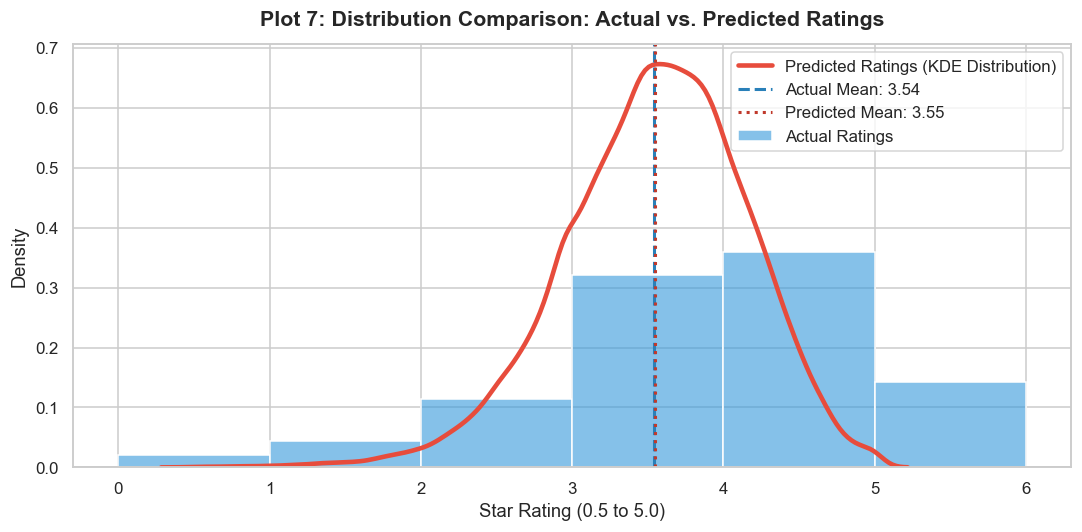

Computing epoch convergence curve for Plot 8...


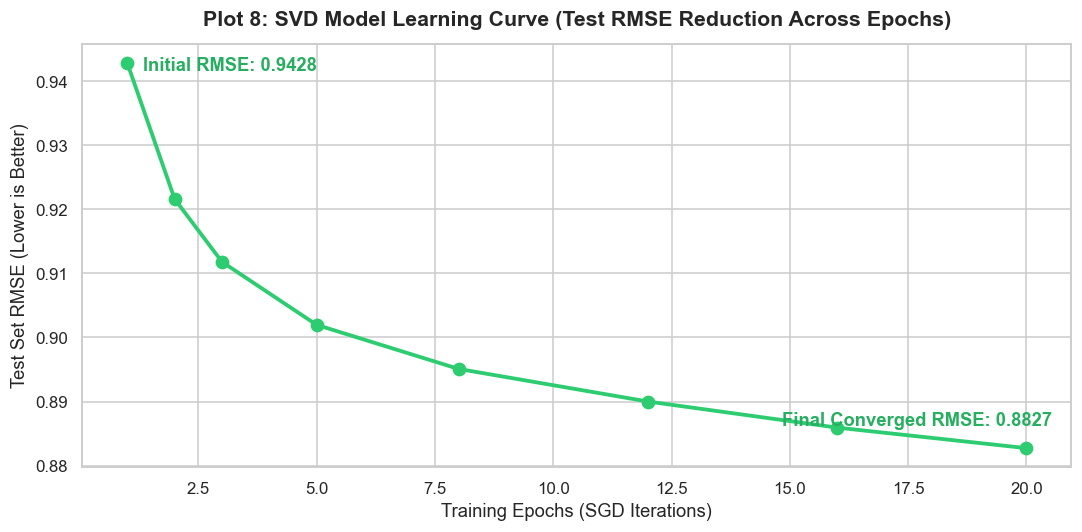

/var/folders/t5/r8ysdt5x2j95xb0t10svdd7r0000gn/T/ipykernel_19976/1813143060.py:114: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


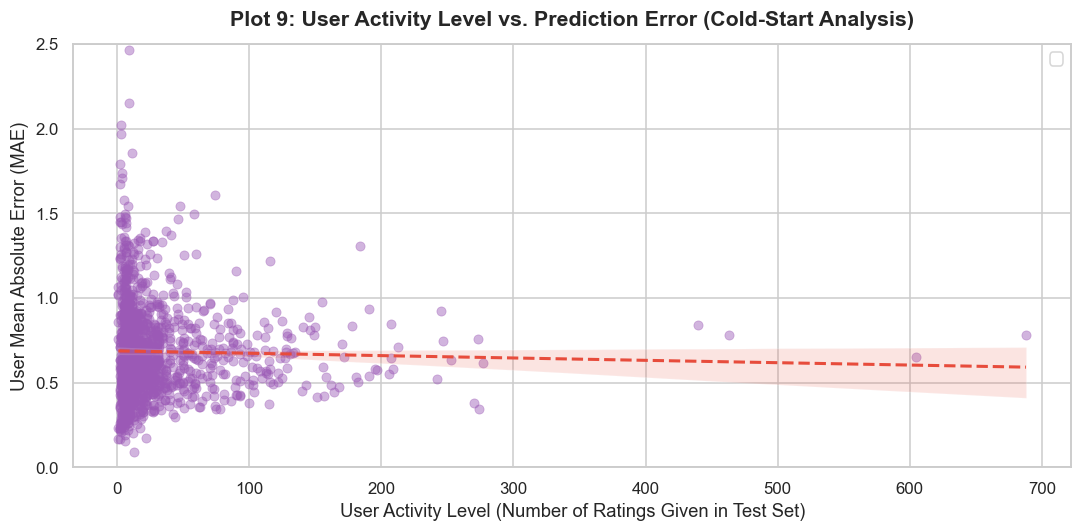

All 3 Collaborative Filtering evaluation plots generated successfully!


In [4]:
# ==============================================================================
# Cell 4 Code: Generate 3 Evaluation & Error Plots
# ==============================================================================

# ------------------------------------------------------------------------------
# Plot 7: Comparison Histogram of Actual Ratings vs. Predicted Ratings
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

actual_ratings = [p.r_ui for p in test_predictions]
predicted_ratings = [p.est for p in test_predictions]

# Plot overlapping distribution histograms
sns.histplot(
    actual_ratings,
    color='#3498db',
    label='Actual Ratings',
    stat='density',
    discrete=True,
    alpha=0.6,
    edgecolor='white'
)
sns.kdeplot(
    predicted_ratings,
    color='#e74c3c',
    label='Predicted Ratings (KDE Distribution)',
    linewidth=3
)

plt.title('Plot 7: Distribution Comparison: Actual vs. Predicted Ratings', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Star Rating (0.5 to 5.0)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.axvline(np.mean(actual_ratings), color='#2980b9', linestyle='--', linewidth=2, label=f'Actual Mean: {np.mean(actual_ratings):.2f}')
plt.axvline(np.mean(predicted_ratings), color='#c0392b', linestyle=':', linewidth=2, label=f'Predicted Mean: {np.mean(predicted_ratings):.2f}')
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 8: Line Chart Showing Training Error Reduction Across Epochs
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

# Evaluate test RMSE across varying numbers of training epochs (1 to 20)
epoch_candidates = [1, 2, 3, 5, 8, 12, 16, 20]
rmse_history = []

print("Computing epoch convergence curve for Plot 8...")
for ep in epoch_candidates:
    temp_svd = SVD(n_factors=50, n_epochs=ep, lr_all=0.005, reg_all=0.02, random_state=42)
    temp_svd.fit(trainset)
    preds = temp_svd.test(testset)
    rmse_history.append(accuracy.rmse(preds, verbose=False))

plt.plot(epoch_candidates, rmse_history, marker='o', color='#2ecc71', linewidth=2.5, markersize=8)
plt.title('Plot 8: SVD Model Learning Curve (Test RMSE Reduction Across Epochs)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Training Epochs (SGD Iterations)', fontsize=12)
plt.ylabel('Test Set RMSE (Lower is Better)', fontsize=12)

# Annotate starting and final RMSE
plt.annotate(
    f"Initial RMSE: {rmse_history[0]:.4f}",
    (epoch_candidates[0], rmse_history[0]),
    textcoords="offset points", xytext=(10, -5), fontweight='bold', color='#27ae60'
)
plt.annotate(
    f"Final Converged RMSE: {rmse_history[-1]:.4f}",
    (epoch_candidates[-1], rmse_history[-1]),
    textcoords="offset points", xytext=(-160, 15), fontweight='bold', color='#27ae60'
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 9: Scatter Plot of User Activity Level vs. Prediction Accuracy
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))

# Group test prediction errors by user
user_errors = defaultdict(list)
for p in test_predictions:
    user_errors[p.uid].append(abs(p.r_ui - p.est))

# Calculate user activity (number of test ratings) and average absolute error
user_activity = [len(errs) for errs in user_errors.values()]
user_mae = [np.mean(errs) for errs in user_errors.values()]

user_stats_df = pd.DataFrame({'Activity (Ratings Count)': user_activity, 'Mean Absolute Error': user_mae})

# Scatter plot with trend line
sns.scatterplot(
    data=user_stats_df,
    x='Activity (Ratings Count)',
    y='Mean Absolute Error',
    alpha=0.45,
    color='#9b59b6',
    edgecolor=None
)
sns.regplot(
    data=user_stats_df,
    x='Activity (Ratings Count)',
    y='Mean Absolute Error',
    scatter=False,
    color='#e74c3c',
    line_kws={'linewidth': 2, 'linestyle': '--', 'label': 'Overall Error Trend'}
)

plt.title('Plot 9: User Activity Level vs. Prediction Error (Cold-Start Analysis)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('User Activity Level (Number of Ratings Given in Test Set)', fontsize=12)
plt.ylabel('User Mean Absolute Error (MAE)', fontsize=12)
plt.ylim(0, 2.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

print("All 3 Collaborative Filtering evaluation plots generated successfully!")